In [1]:
!python -m pip install pyyaml==5.1
!python -m pip install git+https://github.com/facebookresearch/detectron2.git


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-_9q6idcb
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-_9q6idcb
  Resolved https://github.com/facebookresearch/detectron2.git to commit b599f139756bd3646a26a909caf86a1a159e53a7
  Installing build dependencies ... done
  Getting requirements to build wheel ... error
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [17 lines of output]
      Traceback (most recent call last):
        File "/home/podolska/myenv/lib/python3.10/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 389, in <module>
          main()
        File "/home/podolska/myenv/lib/python3.10/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_p

In [1]:
import pandas as pd
import torch, detectron2
from detectron2.utils.logger import setup_logger
from detectron2.engine import DefaultTrainer
from detectron2.data.datasets import register_coco_instances
import matplotlib.image as mpimg
import numpy as np
import os, json, cv2, random
from PIL import Image
from matplotlib import pyplot as plt
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.notebook import tqdm
from detectron2.data import DatasetCatalog, MetadataCatalog, build_detection_test_loader
from detectron2.structures import Boxes, pairwise_iou, BoxMode
from collections import Counter
from pycocotools.coco import COCO
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, hamming_loss, classification_report
import base64
from detectron2.utils.visualizer import ColorMode
import random
from collections import defaultdict, Counter
from detectron2.data.datasets import register_coco_instances
from detectron2.data import DatasetCatalog, MetadataCatalog
setup_logger()
TORCH_VERSION = ".".join(torch.__version__.split(".")[:2])
CUDA_VERSION = torch.__version__.split("+")[-1]

/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
json_path = "./dataset/annotations/instances_default.json"
images_dir = "./dataset/images"

### DRAFT

In [4]:
register_coco_instances("my_food_dataset", {}, json_path, images_dir)

In [5]:
thing_classes = ["Tomato", "Apple", "Avocado", "Banana", "Lettuce", "Carrot",
 "Cornie", "Hard Cheese", "Cookie", "Chocolate", "Mandarin",
 "Egg", "Cucumber", "Yogurt", "Tortilia", "Bread",
 "Mozzarella", "Sausage", "Rice", "Buckwheat", "Chicken", "Pasta"]
MetadataCatalog.get("my_food_dataset").thing_classes = thing_classes

In [6]:
MetadataCatalog.get("my_food_dataset").thing_classes

['Tomato',
 'Apple',
 'Avocado',
 'Banana',
 'Lettuce',
 'Carrot',
 'Cornie',
 'Hard Cheese',
 'Cookie',
 'Chocolate',
 'Mandarin',
 'Egg',
 'Cucumber',
 'Yogurt',
 'Tortilia',
 'Bread',
 'Mozzarella',
 'Sausage',
 'Rice',
 'Buckwheat',
 'Chicken',
 'Pasta']

In [7]:
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))

cfg.DATASETS.TRAIN = ("my_food_dataset",)
cfg.DATASETS.TEST = ()


cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")  

cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 30

cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128

cfg.MODEL.DEVICE = "cuda"
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 22
cfg.SOLVER.CHECKPOINT_PERIOD = 100

In [8]:
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[04/13 15:07:48 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (23, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (23,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (88, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (88,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (22, 256, 1, 

[04/13 15:07:48 d2.engine.train_loop]: Starting training from iteration 0


/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[04/13 15:07:52 d2.utils.events]:  eta: 0:00:01  iter: 19  total_loss: 4.772  loss_cls: 3.077  loss_box_reg: 0.972  loss_mask: 0.6887  loss_rpn_cls: 0.01154  loss_rpn_loc: 0.008517    time: 0.1607  last_time: 0.1650  data_time: 0.0119  last_data_time: 0.0022   lr: 0.00015842  max_mem: 1972M
[04/13 15:07:54 d2.utils.events]:  eta: 0:00:00  iter: 29  total_loss: 3.169  loss_cls: 1.536  loss_box_reg: 0.9614  loss_mask: 0.6719  loss_rpn_cls: 0.006397  loss_rpn_loc: 0.007553    time: 0.1627  last_time: 0.1605  data_time: 0.0023  last_data_time: 0.0024   lr: 0.00024168  max_mem: 1972M
[04/13 15:07:54 d2.engine.hooks]: Overall training speed: 28 iterations in 0:00:04 (0.1627 s / it)
[04/13 15:07:54 d2.engine.hooks]: Total training time: 0:00:05 (0:00:00 on hooks)


[04/13 10:18:49 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output/model_final.pth ...


/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/fvcore/common/checkpoint.py:252: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(f, map_

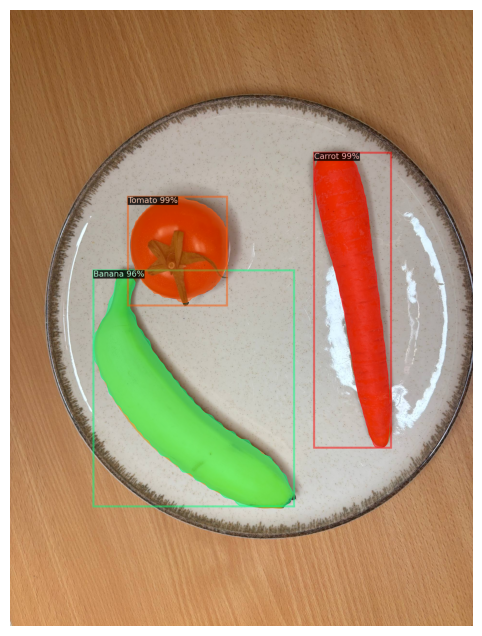

In [12]:
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 22
cfg.MODEL.WEIGHTS = "./output/model_final.pth"
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.6
cfg.MODEL.DEVICE = "cuda"

predictor = DefaultPredictor(cfg)

im = cv2.imread("./dataset/images/photo_2_2026-03-12_22-56-50.jpg")
im_rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

outputs = predictor(im)

v = Visualizer(im_rgb, MetadataCatalog.get("my_food_dataset"), scale=1.0)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

plt.figure(figsize=(12, 8))
plt.imshow(out.get_image())
plt.axis("off")
plt.show()

In [15]:
file_name= "./dataset/images/photo_2_2026-03-12_22-56-50.jpg"

[04/11 17:44:20 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output/model_final.pth ...


/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/fvcore/common/checkpoint.py:252: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(f, map_

[04/11 17:44:20 d2.data.datasets.coco]: Loaded 261 images in COCO format from ./dataset/annotations/instances_default.json


(np.float64(-0.5), np.float64(1919.5), np.float64(2559.5), np.float64(-0.5))

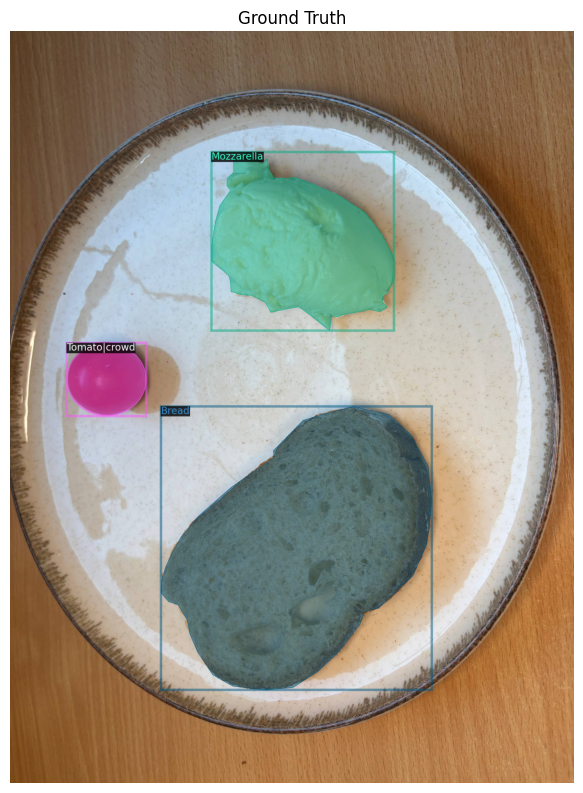

In [16]:
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
))
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 10
cfg.MODEL.WEIGHTS = "./output/model_final.pth"  
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.4
cfg.MODEL.DEVICE = "cpu"

predictor = DefaultPredictor(cfg)


val_dicts = DatasetCatalog.get("my_food_dataset")
metadata = MetadataCatalog.get("my_food_dataset")

sample = random.choice(val_dicts)
img_path = sample["file_name"]
img = cv2.imread(img_path)
img_rgb = img[:, :, ::-1]


v_gt = Visualizer(img_rgb, metadata=metadata)
out_gt = v_gt.draw_dataset_dict(sample)


outputs = predictor(img)
v_pred = Visualizer(img_rgb, metadata=metadata)
out_pred = v_pred.draw_instance_predictions(outputs["instances"].to("cpu"))

plt.figure(figsize=(16, 10))
plt.subplot(1, 2, 1)
plt.imshow(out_gt.get_image())
plt.title("Ground Truth")
plt.axis("off")

### script for spiliting dataset on test train with condidtion, that every category is at least 2 times in test set

In [15]:
TRAIN_JSON = "./train.json"
TEST_JSON = "./test.json"

TEST_RATIO = 0.2
MIN_TEST_PER_CLASS = 2
SEED = 42

random.seed(SEED)

with open(json_path, "r", encoding="utf-8") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = coco["categories"]

image_id_to_image = {img["id"]: img for img in images}
category_id_to_name = {cat["id"]: cat["name"] for cat in categories}

image_to_anns = defaultdict(list)
image_to_cats = defaultdict(set)
total_class_instances = Counter()
total_class_images = Counter()

for ann in annotations:
    image_id = ann["image_id"]
    cat_id = ann["category_id"]
    image_to_anns[image_id].append(ann)
    image_to_cats[image_id].add(cat_id)
    total_class_instances[cat_id] += 1

for image_id, cats in image_to_cats.items():
    for cat_id in cats:
        total_class_images[cat_id] += 1

all_image_ids = list(image_id_to_image.keys())

cat_to_images = defaultdict(set)
for image_id, cats in image_to_cats.items():
    for cat_id in cats:
        cat_to_images[cat_id].add(image_id)

print("Всего изображений:", len(all_image_ids))
print("Всего классов:", len(categories))

impossible_classes = []
for cat in categories:
    cat_id = cat["id"]
    name = cat["name"]
    total_inst = total_class_instances[cat_id]
    total_imgs = total_class_images[cat_id]

    if total_inst < 2 * MIN_TEST_PER_CLASS + 1:
        impossible_classes.append(
            f"{name}: слишком мало instances ({total_inst}), нельзя гарантировать train > test и test >= {MIN_TEST_PER_CLASS}"
        )
    elif total_imgs < MIN_TEST_PER_CLASS:
        impossible_classes.append(
            f"{name}: слишком мало изображений ({total_imgs}), нельзя гарантировать test >= {MIN_TEST_PER_CLASS} изображений"
        )

if impossible_classes:
    print("\nПредупреждение. Для некоторых классов условия могут быть невыполнимы:")
    for msg in impossible_classes:
        print("-", msg)

target_test_size = max(1, int(len(all_image_ids) * TEST_RATIO))

test_ids = set()
train_ids = set(all_image_ids)

test_class_instances = Counter()
test_class_images = Counter()

def can_add_image_to_test(image_id):
    img_cats = image_to_cats.get(image_id, set())
    img_anns = image_to_anns.get(image_id, [])

    add_inst = Counter()
    for ann in img_anns:
        add_inst[ann["category_id"]] += 1

    for cat_id in img_cats:
        new_test_inst = test_class_instances[cat_id] + add_inst[cat_id]
        remaining_train_inst = total_class_instances[cat_id] - new_test_inst
        if remaining_train_inst <= new_test_inst:
            return False

    return True

def add_image_to_test(image_id):
    test_ids.add(image_id)
    train_ids.discard(image_id)

    cats_in_image = image_to_cats.get(image_id, set())
    for cat_id in cats_in_image:
        test_class_images[cat_id] += 1

    for ann in image_to_anns.get(image_id, []):
        test_class_instances[ann["category_id"]] += 1

cat_order = sorted(
    [cat["id"] for cat in categories],
    key=lambda c: (total_class_images[c], total_class_instances[c])
)

for cat_id in cat_order:
    while test_class_images[cat_id] < MIN_TEST_PER_CLASS:
        candidates = list(cat_to_images[cat_id] - test_ids)

        if not candidates:
            break

        candidates.sort(
            key=lambda img_id: (
                -sum(1 for c in image_to_cats[img_id] if test_class_images[c] < MIN_TEST_PER_CLASS),
                -len(image_to_cats[img_id]),
                len(image_to_anns[img_id]),
                random.random()
            )
        )

        added = False
        for img_id in candidates:
            if can_add_image_to_test(img_id):
                add_image_to_test(img_id)
                added = True
                break

        if not added:
            break

remaining_candidates = list(train_ids)
remaining_candidates.sort(
    key=lambda img_id: (
        -sum(1 for c in image_to_cats[img_id] if test_class_images[c] < MIN_TEST_PER_CLASS),
        -len(image_to_cats[img_id]),
        len(image_to_anns[img_id]),
        random.random()
    )
)

for img_id in remaining_candidates:
    if len(test_ids) >= target_test_size:
        break
    if can_add_image_to_test(img_id):
        add_image_to_test(img_id)

def build_subset(selected_ids):
    selected_images = [image_id_to_image[i] for i in selected_ids]
    selected_annotations = []
    for image_id in selected_ids:
        selected_annotations.extend(image_to_anns.get(image_id, []))

    subset = {
        "images": selected_images,
        "annotations": selected_annotations,
        "categories": categories
    }

    for k, v in coco.items():
        if k not in subset:
            subset[k] = v

    return subset

train_coco = build_subset(train_ids)
test_coco = build_subset(test_ids)

with open(TRAIN_JSON, "w", encoding="utf-8") as f:
    json.dump(train_coco, f, ensure_ascii=False, indent=2)

with open(TEST_JSON, "w", encoding="utf-8") as f:
    json.dump(test_coco, f, ensure_ascii=False, indent=2)

train_class_instances = Counter()
train_class_images = Counter()

for image_id in train_ids:
    for cat_id in image_to_cats.get(image_id, set()):
        train_class_images[cat_id] += 1
    for ann in image_to_anns.get(image_id, []):
        train_class_instances[ann["category_id"]] += 1

print("\n=== ИТОГ ===")
print("Train images:", len(train_ids))
print("Test images:", len(test_ids))
print("Test ratio:", round(len(test_ids) / len(all_image_ids), 4))

print("\n=== Проверка по классам ===")
all_ok = True
for cat in categories:
    cat_id = cat["id"]
    name = cat["name"]

    tr_i = train_class_instances[cat_id]
    te_i = test_class_instances[cat_id]
    tr_img = train_class_images[cat_id]
    te_img = test_class_images[cat_id]

    ok_min_test = te_img >= MIN_TEST_PER_CLASS
    ok_train_more = tr_i > te_i

    if not (ok_min_test and ok_train_more):
        all_ok = False

    print(
        f"{name}: "
        f"train_instances={tr_i}, test_instances={te_i}, "
        f"train_images={tr_img}, test_images={te_img}, "
        f"min_test_ok={ok_min_test}, train_gt_test_ok={ok_train_more}"
    )

print("\nВсе условия выполнены:" , all_ok)

Всего изображений: 261
Всего классов: 22

=== ИТОГ ===
Train images: 209
Test images: 52
Test ratio: 0.1992

=== Проверка по классам ===
Tomato: train_instances=52, test_instances=9, train_images=52, test_images=9, min_test_ok=True, train_gt_test_ok=True
Apple: train_instances=29, test_instances=12, train_images=29, test_images=12, min_test_ok=True, train_gt_test_ok=True
Avocado: train_instances=54, test_instances=18, train_images=54, test_images=18, min_test_ok=True, train_gt_test_ok=True
Banana: train_instances=39, test_instances=10, train_images=39, test_images=10, min_test_ok=True, train_gt_test_ok=True
Lettuce: train_instances=28, test_instances=11, train_images=28, test_images=11, min_test_ok=True, train_gt_test_ok=True
Carrot: train_instances=47, test_instances=10, train_images=46, test_images=10, min_test_ok=True, train_gt_test_ok=True
Cornie: train_instances=43, test_instances=12, train_images=43, test_images=12, min_test_ok=True, train_gt_test_ok=True
Hard Cheese: train_insta

In [18]:
for name in ["my_food_train", "my_food_test", "my_food_dataset"]:
    if name in DatasetCatalog.list():
        DatasetCatalog.remove(name)
    MetadataCatalog.remove(name)

### Start from here

In [3]:
register_coco_instances("my_food_train", {}, "./train.json", images_dir)
register_coco_instances("my_food_test", {}, "./test.json", images_dir)

thing_classes = ["Tomato", "Apple", "Avocado", "Banana", "Lettuce", "Carrot",
 "Cornie", "Hard Cheese", "Cookie", "Chocolate", "Mandarin",
 "Egg", "Cucumber", "Yogurt", "Tortilia", "Bread",
 "Mozzarella", "Sausage", "Rice", "Buckwheat", "Chicken", "Pasta"]

MetadataCatalog.get("my_food_train").thing_classes = thing_classes
MetadataCatalog.get("my_food_test").thing_classes = thing_classes

In [5]:
import os
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer
from detectron2.data import build_detection_train_loader, DatasetMapper
import detectron2.data.transforms as T
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader
from detectron2.checkpoint import DetectionCheckpointer


class MyTrainer(DefaultTrainer):
    @classmethod
    def build_train_loader(cls, cfg):
        mapper = DatasetMapper(
            cfg,
            is_train=True,
            augmentations=[
                T.ResizeShortestEdge(
                    short_edge_length=(640, 672, 704, 736, 768, 800),
                    max_size=1333,
                    sample_style="choice"
                ),
                T.RandomFlip(horizontal=True, vertical=False),
                T.RandomBrightness(0.9, 1.1),
                T.RandomContrast(0.9, 1.1),
                T.RandomSaturation(0.9, 1.1),
                T.RandomRotation(angle=[-5, 5]),
            ]
        )
        return build_detection_train_loader(cfg, mapper=mapper)

    @classmethod
    def build_evaluator(cls, cfg, dataset_name, output_folder=None):
        if output_folder is None:
            output_folder = os.path.join(cfg.OUTPUT_DIR, "inference", dataset_name)
        return COCOEvaluator(dataset_name, cfg, False, output_folder)


cfg = get_cfg()
cfg.merge_from_file(
    model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
)

cfg.DATASETS.TRAIN = ("my_food_train",)
cfg.DATASETS.TEST = ("my_food_test",)

cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
)

cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 4000
cfg.SOLVER.CHECKPOINT_PERIOD = 500

cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 22
cfg.MODEL.DEVICE = "cuda"

cfg.TEST.EVAL_PERIOD = 500

cfg.OUTPUT_DIR = "./output_train_test"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

# ---------- TRAIN ----------
trainer = MyTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

# ---------- LOAD BEST/LAST MODEL ----------
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
predictor_model = trainer.build_model(cfg)
DetectionCheckpointer(predictor_model).load(cfg.MODEL.WEIGHTS)

# ---------- EVALUATE ON CLEAN TRAIN ----------
train_evaluator = COCOEvaluator("my_food_train", cfg, False, output_dir=os.path.join(cfg.OUTPUT_DIR, "eval_train"))
train_loader = build_detection_test_loader(cfg, "my_food_train")
train_results = inference_on_dataset(predictor_model, train_loader, train_evaluator)

print("\nCLEAN TRAIN RESULTS:")
print(train_results)

# ---------- EVALUATE ON CLEAN TEST ----------
test_evaluator = COCOEvaluator("my_food_test", cfg, False, output_dir=os.path.join(cfg.OUTPUT_DIR, "eval_test"))
test_loader = build_detection_test_loader(cfg, "my_food_test")
test_results = inference_on_dataset(predictor_model, test_loader, test_evaluator)

print("\nCLEAN TEST RESULTS:")
print(test_results)

[04/21 11:07:19 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (23, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (23,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (88, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (88,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (22, 256, 1, 

[04/21 11:07:19 d2.engine.train_loop]: Starting training from iteration 0


/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[04/21 11:07:23 d2.utils.events]:  eta: 0:12:05  iter: 19  total_loss: 4.895  loss_cls: 3.214  loss_box_reg: 0.9615  loss_mask: 0.6941  loss_rpn_cls: 0.01203  loss_rpn_loc: 0.009315    time: 0.1813  last_time: 0.1764  data_time: 0.0122  last_data_time: 0.0017   lr: 4.9953e-06  max_mem: 2428M
[04/21 11:07:27 d2.utils.events]:  eta: 0:12:01  iter: 39  total_loss: 4.714  loss_cls: 3.092  loss_box_reg: 0.9335  loss_mask: 0.69  loss_rpn_cls: 0.007562  loss_rpn_loc: 0.007264    time: 0.1819  last_time: 0.1816  data_time: 0.0023  last_data_time: 0.0026   lr: 9.9902e-06  max_mem: 2428M
[04/21 11:07:31 d2.utils.events]:  eta: 0:11:57  iter: 59  total_loss: 4.392  loss_cls: 2.703  loss_box_reg: 0.9512  loss_mask: 0.6873  loss_rpn_cls: 0.009375  loss_rpn_loc: 0.008943    time: 0.1791  last_time: 0.2067  data_time: 0.0023  last_data_time: 0.0020   lr: 1.4985e-05  max_mem: 2428M
[04/21 11:07:34 d2.utils.events]:  eta: 0:11:54  iter: 79  total_loss: 3.807  loss_cls: 2.181  loss_box_reg: 0.9424  loss

/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/fvcore/common/checkpoint.py:252: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  return torch.load(f, map_

[04/21 11:20:40 d2.evaluation.evaluator]: Inference done 22/209. Dataloading: 0.0009 s/iter. Inference: 0.0426 s/iter. Eval: 0.0161 s/iter. Total: 0.0596 s/iter. ETA=0:00:11
[04/21 11:20:46 d2.evaluation.evaluator]: Inference done 106/209. Dataloading: 0.0010 s/iter. Inference: 0.0427 s/iter. Eval: 0.0164 s/iter. Total: 0.0601 s/iter. ETA=0:00:06
[04/21 11:20:51 d2.evaluation.evaluator]: Inference done 182/209. Dataloading: 0.0009 s/iter. Inference: 0.0429 s/iter. Eval: 0.0187 s/iter. Total: 0.0626 s/iter. ETA=0:00:01
[04/21 11:20:52 d2.evaluation.evaluator]: Total inference time: 0:00:12.725757 (0.062381 s / iter per device, on 1 devices)
[04/21 11:20:52 d2.evaluation.evaluator]: Total inference pure compute time: 0:00:08 (0.042874 s / iter per device, on 1 devices)
[04/21 11:20:52 d2.evaluation.coco_evaluation]: Preparing results for COCO format ...
[04/21 11:20:52 d2.evaluation.coco_evaluation]: Saving results to ./output_train_test/eval_train/coco_instances_results.json
[04/21 11:2

### Multi-label metrics

In [23]:
predictor = DefaultPredictor(cfg)
def evaluate_dataset(predictor, dataset_name, score_thresh):
    metadata = MetadataCatalog.get(dataset_name)
    ann_file = metadata.json_file
    coco = COCO(ann_file)
    all_classes = metadata.thing_classes

    y_true_all = []
    y_pred_all = []

    dataset_dicts = DatasetCatalog.get(dataset_name)

    file_to_img_id = {}
    for img_id in coco.getImgIds():
        info = coco.loadImgs(img_id)[0]
        file_to_img_id[info["file_name"].split("/")[-1]] = img_id

    cat_id_to_name = {}
    for cat in coco.loadCats(coco.getCatIds()):
        cat_id_to_name[cat["id"]] = cat["name"]

    for d in tqdm(dataset_dicts, desc=f"Evaluating {dataset_name}"):
        filename = d["file_name"].split("/")[-1]
        img_id = file_to_img_id.get(filename)

        if img_id is None:
            continue

        ann_ids = coco.getAnnIds(imgIds=[img_id])
        anns = coco.loadAnns(ann_ids)
        y_true = [cat_id_to_name[ann["category_id"]] for ann in anns]

        img = cv2.imread(d["file_name"])
        if img is None:
            continue

        outputs = predictor(img)
        instances = outputs["instances"].to("cpu")

        if instances.has("scores"):
            keep = instances.scores > score_thresh
            instances = instances[keep]

        y_pred = [all_classes[c.item()] for c in instances.pred_classes] if instances.has("pred_classes") else []

        y_true_set = set(y_true)
        y_pred_set = set(y_pred)

        y_true_vec = [1 if c in y_true_set else 0 for c in all_classes]
        y_pred_vec = [1 if c in y_pred_set else 0 for c in all_classes]

        y_true_all.append(y_true_vec)
        y_pred_all.append(y_pred_vec)

    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)

    subset_acc = np.mean([np.array_equal(t, p) for t, p in zip(y_true_all, y_pred_all)])
    hamming_acc = 1 - hamming_loss(y_true_all, y_pred_all)
    prec_macro = precision_score(y_true_all, y_pred_all, average="macro", zero_division=0)
    rec_macro = recall_score(y_true_all, y_pred_all, average="macro", zero_division=0)
    f1_macro = f1_score(y_true_all, y_pred_all, average="macro", zero_division=0)

    return {
        "subset_accuracy": subset_acc,
        "hamming_accuracy": hamming_acc,
        "precision_macro": prec_macro,
        "recall_macro": rec_macro,
        "f1_macro": f1_macro
    }

score_thresholds = [0.5, 0.7]

for thresh in score_thresholds:
    print(f"\nEvaluating with score_thresh = {thresh}")

    metrics_train = evaluate_dataset(predictor, "my_food_train", score_thresh=thresh)
    print("\nTrain results:")
    for k, v in metrics_train.items():
        print(f"{k}: {v:.3f}")

    metrics_test = evaluate_dataset(predictor, "my_food_test", score_thresh=thresh)
    print("\nTest results:")
    for k, v in metrics_test.items():
        print(f"{k}: {v:.3f}")

[04/13 15:43:49 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from https://dl.fbaipublicfiles.com/detectron2/COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x/137849600/model_final_f10217.pkl ...


Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (23, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (23,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (88, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (88,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (22, 256, 1, 


Evaluating with score_thresh = 0.5
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
[04/13 15:43:49 d2.data.datasets.coco]: Loaded 209 images in COCO format from ./train.json


Evaluating my_food_train:   0%|          | 0/209 [00:00<?, ?it/s]


Train results:
subset_accuracy: 0.005
hamming_accuracy: 0.864
precision_macro: 0.000
recall_macro: 0.000
f1_macro: 0.000
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
[04/13 15:44:59 d2.data.datasets.coco]: Loaded 52 images in COCO format from ./test.json


...


Test results:
subset_accuracy: 0.000
hamming_accuracy: 0.839
precision_macro: 0.000
recall_macro: 0.000
f1_macro: 0.000

Evaluating with score_thresh = 0.7
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
[04/13 15:45:17 d2.data.datasets.coco]: Loaded 209 images in COCO format from ./train.json


Evaluating my_food_train:   0%|          | 0/209 [00:00<?, ?it/s]


Train results:
subset_accuracy: 0.005
hamming_accuracy: 0.864
precision_macro: 0.000
recall_macro: 0.000
f1_macro: 0.000
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
[04/13 15:46:27 d2.data.datasets.coco]: Loaded 52 images in COCO format from ./test.json


Evaluating my_food_test:   0%|          | 0/52 [00:00<?, ?it/s]


Test results:
subset_accuracy: 0.000
hamming_accuracy: 0.839
precision_macro: 0.000
recall_macro: 0.000
f1_macro: 0.000


### Multi-class classification F1 score

[04/21 11:37:31 d2.data.datasets.coco]: Loaded 209 images in COCO format from ./train.json
[04/21 11:37:31 d2.data.datasets.coco]: Loaded 209 images in COCO format from ./train.json
[04/21 11:37:31 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[04/21 11:37:31 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[04/21 11:37:31 d2.data.common]: Serializing 209 elements to byte tensors and concatenating them all ...
[04/21 11:37:31 d2.data.common]: Serialized dataset takes 0.83 MiB


Evaluating my_food_train:   0%|          | 0/209 [00:00<?, ?it/s]

[04/21 11:37:43 d2.data.datasets.coco]: Loaded 52 images in COCO format from ./test.json
[04/21 11:37:43 d2.data.datasets.coco]: Loaded 52 images in COCO format from ./test.json
[04/21 11:37:43 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[04/21 11:37:43 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[04/21 11:37:43 d2.data.common]: Serializing 52 elements to byte tensors and concatenating them all ...
[04/21 11:37:43 d2.data.common]: Serialized dataset takes 0.28 MiB


Evaluating my_food_test:   0%|          | 0/52 [00:00<?, ?it/s]

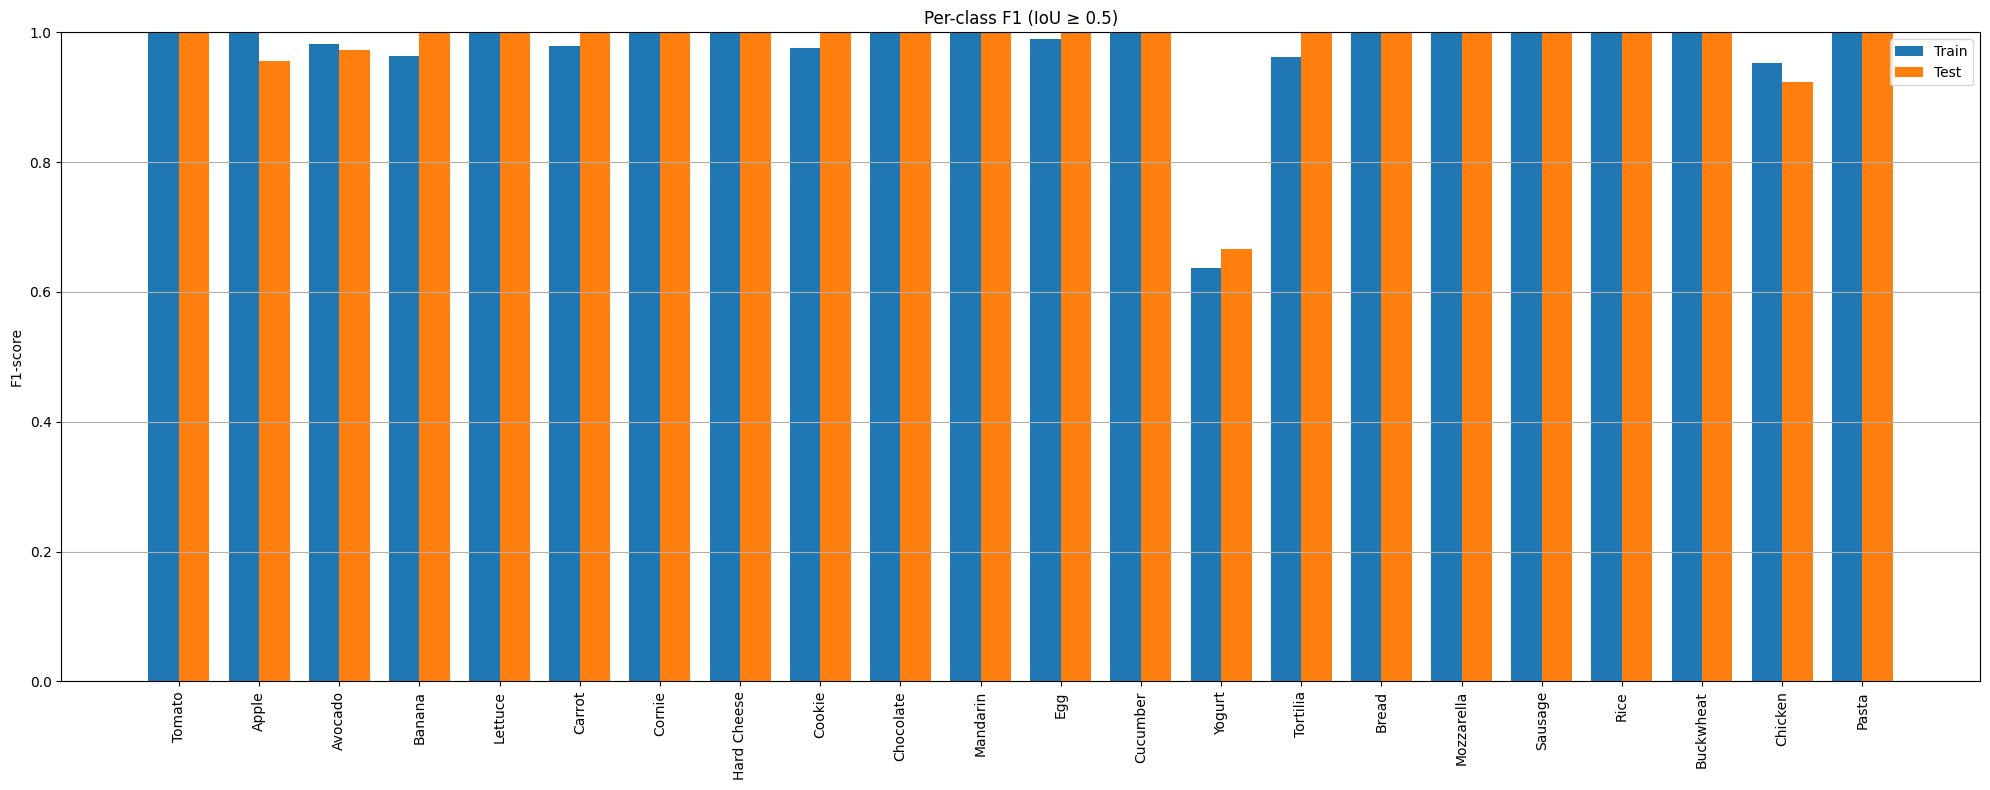


TRAIN
Tomato               -> F1=1.000, P=1.000, R=1.000
Apple                -> F1=1.000, P=1.000, R=1.000
Avocado              -> F1=0.982, P=0.964, R=1.000
Banana               -> F1=0.963, P=0.929, R=1.000
Lettuce              -> F1=1.000, P=1.000, R=1.000
Carrot               -> F1=0.979, P=0.959, R=1.000
Cornie               -> F1=1.000, P=1.000, R=1.000
Hard Cheese          -> F1=1.000, P=1.000, R=1.000
Cookie               -> F1=0.976, P=0.952, R=1.000
Chocolate            -> F1=1.000, P=1.000, R=1.000
Mandarin             -> F1=1.000, P=1.000, R=1.000
Egg                  -> F1=0.990, P=0.980, R=1.000
Cucumber             -> F1=1.000, P=1.000, R=1.000
Yogurt               -> F1=0.636, P=1.000, R=0.467
Tortilia             -> F1=0.962, P=0.926, R=1.000
Bread                -> F1=1.000, P=1.000, R=1.000
Mozzarella           -> F1=1.000, P=1.000, R=1.000
Sausage              -> F1=1.000, P=1.000, R=1.000
Rice                 -> F1=1.000, P=1.000, R=1.000
Buckwheat            -> 

In [6]:
def compute_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)
    if inter <= 0:
        return 0.0

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - inter

    return inter / union if union > 0 else 0.0

def evaluate_per_class_f1(model, cfg, dataset_name, iou_thresh=0.5, score_thresh=0.5):
    dataset_dicts = DatasetCatalog.get(dataset_name)
    class_names = MetadataCatalog.get(dataset_name).thing_classes
    num_classes = len(class_names)

    gt_boxes_all = []
    gt_classes_all = []

    for item in dataset_dicts:
        boxes = []
        classes = []
        for ann in item["annotations"]:
            x, y, w, h = ann["bbox"]
            boxes.append([x, y, x + w, y + h])
            classes.append(ann["category_id"])
        gt_boxes_all.append(np.array(boxes, dtype=np.float32))
        gt_classes_all.append(np.array(classes, dtype=np.int64))

    data_loader = build_detection_test_loader(cfg, dataset_name)

    pred_boxes_all = []
    pred_scores_all = []
    pred_classes_all = []

    model.eval()
    with torch.no_grad():
        for batch in tqdm(data_loader, desc=f"Evaluating {dataset_name}"):
            outputs = model(batch)
            for out in outputs:
                instances = out["instances"].to("cpu")

                boxes = instances.pred_boxes.tensor.numpy() if instances.has("pred_boxes") else np.zeros((0, 4))
                scores = instances.scores.numpy() if instances.has("scores") else np.array([])
                classes = instances.pred_classes.numpy() if instances.has("pred_classes") else np.array([])

                keep = scores >= score_thresh if len(scores) > 0 else np.array([], dtype=bool)

                pred_boxes_all.append(boxes[keep] if len(scores) > 0 else boxes)
                pred_scores_all.append(scores[keep] if len(scores) > 0 else scores)
                pred_classes_all.append(classes[keep] if len(scores) > 0 else classes)

    TP = np.zeros(num_classes)
    FP = np.zeros(num_classes)
    FN = np.zeros(num_classes)

    for i in range(len(gt_boxes_all)):
        gt_boxes = gt_boxes_all[i]
        gt_classes = gt_classes_all[i]

        pred_boxes = pred_boxes_all[i]
        pred_scores = pred_scores_all[i]
        pred_classes = pred_classes_all[i]

        order = np.argsort(-pred_scores) if len(pred_scores) > 0 else np.array([], dtype=int)
        pred_boxes = pred_boxes[order] if len(order) > 0 else pred_boxes
        pred_classes = pred_classes[order] if len(order) > 0 else pred_classes

        matched_gt = set()

        for pred_idx, (pb, pc) in enumerate(zip(pred_boxes, pred_classes)):
            best_iou = 0
            best_gt_idx = None

            for gt_idx, (gb, gc) in enumerate(zip(gt_boxes, gt_classes)):
                if gt_idx in matched_gt:
                    continue

                iou = compute_iou(pb, gb)
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = gt_idx

            if best_gt_idx is not None and best_iou >= iou_thresh:
                gt_cls = gt_classes[best_gt_idx]

                if pc == gt_cls:
                    TP[pc] += 1
                else:
                    FP[pc] += 1
                    FN[gt_cls] += 1

                matched_gt.add(best_gt_idx)
            else:
                FP[pc] += 1

        for gt_idx, gt_cls in enumerate(gt_classes):
            if gt_idx not in matched_gt:
                FN[gt_cls] += 1

    precision = TP / np.maximum(TP + FP, 1e-6)
    recall = TP / np.maximum(TP + FN, 1e-6)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-6)

    return class_names, f1, precision, recall, TP, FP, FN

train_class_names, train_f1, train_prec, train_rec, *_ = evaluate_per_class_f1(
    trainer.model, cfg, "my_food_train", iou_thresh=0.5, score_thresh=0.5
)

test_class_names, test_f1, test_prec, test_rec, *_ = evaluate_per_class_f1(
    trainer.model, cfg, "my_food_test", iou_thresh=0.5, score_thresh=0.5
)

x = np.arange(len(train_class_names))
width = 0.38

plt.figure(figsize=(20, 8))
plt.bar(x - width/2, train_f1, width, label="Train")
plt.bar(x + width/2, test_f1, width, label="Test")

plt.xticks(x, train_class_names, rotation=90)
plt.ylim(0, 1)
plt.ylabel("F1-score")
plt.title("Per-class F1 (IoU ≥ 0.5)")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

print("\nTRAIN")
for cname, f1, p, r in zip(train_class_names, train_f1, train_prec, train_rec):
    print(f"{cname:20s} -> F1={f1:.3f}, P={p:.3f}, R={r:.3f}")

print("\nTEST")
for cname, f1, p, r in zip(test_class_names, test_f1, test_prec, test_rec):
    print(f"{cname:20s} -> F1={f1:.3f}, P={p:.3f}, R={r:.3f}")

### GPT DATASET

In [17]:
import json
import random
from collections import defaultdict, Counter
from copy import deepcopy

from detectron2.data.datasets import register_coco_instances

INPUT_JSON = "./dataset/annotations_gpt/instances_default.json"
TRAIN_JSON = "train_annotations_gpt.json"
TEST_JSON = "test_annotations_gpt.json"
IMAGE_ROOT = "./dataset/gpt_images"

TEST_RATIO = 0.2
SEED = 42

In [22]:
def split_groups(groups, image_to_classes, category_ids, test_ratio=0.2, seed=42, max_attempts=20000):
    random.seed(seed)

    total_images = sum(len(g) for g in groups)
    target_test_size = int(total_images * test_ratio)

    all_image_ids = set()
    for group in groups:
        all_image_ids.update(group)

    best_split = None
    best_score = float("inf")

    for _ in range(max_attempts):
        shuffled_groups = groups[:]
        random.shuffle(shuffled_groups)

        test_ids = set()
        train_ids = set(all_image_ids)

        test_counts = Counter()

        # 1. Сначала стараемся дать каждому классу хотя бы 1 пример в test
        for class_id in category_ids:
            if test_counts[class_id] > 0:
                continue

            candidate_groups = []

            for group in shuffled_groups:
                group_set = set(group)

                if group_set & test_ids:
                    continue

                group_classes = set()
                for image_id in group:
                    group_classes.update(image_to_classes[image_id])

                if class_id in group_classes:
                    candidate_groups.append(group)

            if candidate_groups:
                # выбираем самую маленькую группу, чтобы test не разрастался
                best_group = min(candidate_groups, key=len)

                for image_id in best_group:
                    test_ids.add(image_id)
                    train_ids.discard(image_id)
                    test_counts.update(image_to_classes[image_id])

        # 2. Добавляем группы в test ближе к TEST_RATIO
        remaining_groups = []

        for group in shuffled_groups:
            group_set = set(group)

            if not (group_set & test_ids):
                remaining_groups.append(group)

        random.shuffle(remaining_groups)

        for group in remaining_groups:
            if len(test_ids) >= target_test_size:
                break

            group_set = set(group)

            # пробуем не добавлять группу, если она сломает train > test слишком сильно
            test_ids_candidate = test_ids | group_set
            train_ids_candidate = all_image_ids - test_ids_candidate

            test_counts_candidate = count_classes(test_ids_candidate, image_to_classes)
            train_counts_candidate = count_classes(train_ids_candidate, image_to_classes)

            bad_classes = 0
            for class_id in category_ids:
                if train_counts_candidate[class_id] <= test_counts_candidate[class_id]:
                    bad_classes += 1

            if bad_classes <= 2:
                test_ids = test_ids_candidate
                train_ids = train_ids_candidate

        train_counts = count_classes(train_ids, image_to_classes)
        test_counts = count_classes(test_ids, image_to_classes)

        missing_in_test = 0
        missing_in_train = 0
        train_not_bigger = 0

        for class_id in category_ids:
            if test_counts[class_id] < 1:
                missing_in_test += 1

            if train_counts[class_id] < 1:
                missing_in_train += 1

            if train_counts[class_id] <= test_counts[class_id]:
                train_not_bigger += 1

        size_penalty = abs(len(test_ids) - target_test_size)

        score = (
            missing_in_test * 10000 +
            missing_in_train * 10000 +
            train_not_bigger * 1000 +
            size_penalty
        )

        if score < best_score:
            best_score = score
            best_split = train_ids, test_ids

            if score == 0:
                break

    train_ids, test_ids = best_split

    train_counts = count_classes(train_ids, image_to_classes)
    test_counts = count_classes(test_ids, image_to_classes)

    print("Лучшее найденное разбиение:")
    print(f"Train images: {len(train_ids)}")
    print(f"Test images:  {len(test_ids)}")
    print()

    problems = []

    for class_id in category_ids:
        if test_counts[class_id] < 1:
            problems.append((class_id, "нет в test"))

        elif train_counts[class_id] < 1:
            problems.append((class_id, "нет в train"))

        elif train_counts[class_id] <= test_counts[class_id]:
            problems.append((class_id, "train <= test"))

    if problems:
        print("Идеальное условие выполнить не удалось.")
        print("Проблемные классы:")
        for class_id, problem in problems:
            print(f"class_id={class_id}: {problem}")
    else:
        print("Все условия выполнены.")

    return train_ids, test_ids

In [23]:
coco = load_coco(INPUT_JSON)

category_ids = [cat["id"] for cat in coco["categories"]]

image_to_classes = get_image_classes(coco)
groups = group_images_by_class_set(image_to_classes)

train_ids, test_ids = split_groups(
    groups=groups,
    image_to_classes=image_to_classes,
    category_ids=category_ids,
    test_ratio=TEST_RATIO,
    seed=SEED
)

train_coco = make_coco_subset(coco, train_ids)
test_coco = make_coco_subset(coco, test_ids)

save_json(train_coco, TRAIN_JSON)
save_json(test_coco, TEST_JSON)

print_split_stats(train_ids, test_ids, image_to_classes, coco["categories"])

Лучшее найденное разбиение:
Train images: 122
Test images:  43

Идеальное условие выполнить не удалось.
Проблемные классы:
class_id=1: нет в train
class_id=2: нет в train
class_id=10: нет в train
class_id=26: train <= test
class_id=28: train <= test
class_id=29: нет в train
class_id=30: нет в train
class_id=31: нет в train
class_id=32: нет в train
Train images: 122
Test images: 43

01 Tortilla             | train:   0 | test:   3
02 Cornie               | train:   0 | test:   4
03 Steak                | train:  12 | test:   6
04 Burger               | train:  15 | test:   3
05 Pizza                | train:  17 | test:   4
06 Chicken              | train:  12 | test:  10
07 Salmon               | train:  18 | test:   3
08 Sausage              | train:   6 | test:   3
09 Bread                | train:   6 | test:   3
10 Apple                | train:   0 | test:   9
11 Pasta                | train:   9 | test:   3
12 Rice                 | train:  12 | test:   7
13 Fries                | t

In [24]:
register_datasets()

print("Registered:")
print("ingredients_train")
print("ingredients_test")

Registered:
ingredients_train
ingredients_test


In [25]:
import os

from detectron2.data.datasets import register_coco_instances
from detectron2.data import MetadataCatalog

images_dir = "./dataset/gpt_images"

register_coco_instances(
    "ingredients_train",
    {},
    "train_annotations_gpt.json",
    images_dir
)

register_coco_instances(
    "ingredients_test",
    {},
    "test_annotations_gpt.json",
    images_dir
)

thing_classes = [
  "Tortilla", "Cornie", "Steak", "Burger", "Pizza", "Chicken", "Salmon",
    "Sausage", "Bread", "Apple", "Pasta", "Rice", "Fries",
    "Sushi Philadelphia", "Potato", "Broccoli", "Tomato", "Onion",
    "Mushrooms", "Lettuce", "Cucumber", "Carrot", "Beans", "Buckwheat",
    "Mozzarella", "Cheese", "Egg", "Yogurt", "Cookie", "Chocolate",
    "Banana", "Mandarin", "Avocado", "Nuts", "Pepper", "Beetroot",
    "Soy Sauce"
]

MetadataCatalog.get("ingredients_train").thing_classes = thing_classes
MetadataCatalog.get("ingredients_test").thing_classes = thing_classes

In [7]:
import os

from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer
from detectron2.data import build_detection_train_loader, DatasetMapper
import detectron2.data.transforms as T
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader
from detectron2.checkpoint import DetectionCheckpointer


class MyTrainer(DefaultTrainer):
    @classmethod
    def build_train_loader(cls, cfg):
        mapper = DatasetMapper(
            cfg,
            is_train=True,
            augmentations=[
                T.ResizeShortestEdge(
                    short_edge_length=(640, 672, 704, 736, 768, 800),
                    max_size=1333,
                    sample_style="choice"
                ),
                T.RandomFlip(horizontal=True, vertical=False),
                T.RandomBrightness(0.9, 1.1),
                T.RandomContrast(0.9, 1.1),
                T.RandomSaturation(0.9, 1.1),
                T.RandomRotation(angle=[-5, 5]),
            ]
        )
        return build_detection_train_loader(cfg, mapper=mapper)

    @classmethod
    def build_evaluator(cls, cfg, dataset_name, output_folder=None):
        if output_folder is None:
            output_folder = os.path.join(cfg.OUTPUT_DIR, "inference", dataset_name)
        return COCOEvaluator(dataset_name, cfg, False, output_folder)

In [27]:
cfg = get_cfg()

cfg.merge_from_file(
    model_zoo.get_config_file(
        "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
    )
)

cfg.DATASETS.TRAIN = ("ingredients_train",)
cfg.DATASETS.TEST = ("ingredients_test",)

cfg.DATALOADER.NUM_WORKERS = 2

cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
)

cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 2000
cfg.SOLVER.CHECKPOINT_PERIOD = 500

cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 37
cfg.MODEL.DEVICE = "cuda"

cfg.TEST.EVAL_PERIOD = 500

cfg.OUTPUT_DIR = "./output_ingredients_train_test"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

In [28]:
trainer = MyTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[05/06 21:44:08 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

AssertionError: No valid data found in ingredients_train.

In [20]:
from detectron2.data import DatasetCatalog, MetadataCatalog

for dataset_name in ["ingredients_train", "ingredients_test"]:
    if dataset_name in DatasetCatalog.list():
        DatasetCatalog.remove(dataset_name)
        MetadataCatalog.remove(dataset_name)

In [30]:
print("TRAIN:")
print("images:", len(train_coco["images"]))
print("annotations:", len(train_coco["annotations"]))

print("\nTEST:")
print("images:", len(test_coco["images"]))
print("annotations:", len(test_coco["annotations"]))

TRAIN:
images: 122
annotations: 352

TEST:
images: 43
annotations: 131


In [31]:
save_json(train_coco, "./train_annotations_gpt.json")
save_json(test_coco, "./test_annotations_gpt.json")

In [39]:
import json

def fix_iscrowd(json_path, output_path):
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for ann in data["annotations"]:
        ann["iscrowd"] = 0

    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)

fix_iscrowd("./train_annotations_gpt.json", "./train_annotations_gpt.json")
fix_iscrowd("./test_annotations_gpt.json", "./test_annotations_gpt.json")

In [40]:
from detectron2.data import DatasetCatalog, MetadataCatalog

for name in ["ingredients_train", "ingredients_test"]:
    if name in DatasetCatalog.list():
        DatasetCatalog.remove(name)
    if name in MetadataCatalog.list():
        MetadataCatalog.remove(name)

In [41]:
from detectron2.data.datasets import register_coco_instances

register_coco_instances(
    "ingredients_train",
    {},
    "train_annotations_gpt.json",
    images_dir
)

register_coco_instances(
    "ingredients_test",
    {},
    "test_annotations_gpt.json",
    images_dir
)

In [42]:
from detectron2.data import DatasetCatalog

train_dicts = DatasetCatalog.get("ingredients_train")
test_dicts = DatasetCatalog.get("ingredients_test")

print(len(train_dicts))
print(len(test_dicts))
print(train_dicts[0])

[05/06 21:48:52 d2.data.datasets.coco]: Loaded 122 images in COCO format from train_annotations_gpt.json
[05/06 21:48:52 d2.data.datasets.coco]: Loaded 43 images in COCO format from test_annotations_gpt.json
122
43
{'file_name': './dataset/gpt_images/photo_103_2026-04-28_11-03-50.jpg', 'height': 1254, 'width': 1254, 'image_id': 4, 'annotations': [{'iscrowd': 0, 'bbox': [48.0, 497.0, 548.0, 523.0], 'category_id': 26, 'segmentation': {'size': [1254, 1254], 'counts': b'mbk11QW19I4M2N2N2N1O2N2M3M2N3N1O1O2N1O2N1O2N1N2O2M2O2O0O2N100O2N1O2N1O100O10001O00000000001O000O101O001N100O2O0O101N10000O2N1O2M2O2N1O1N3M2M4L4L4VmNkL^Q1Y3_nNmLYQ1Y3cnNjLZQ1Y3dnNiLZQ1X3fnNhLXQ1[3fnNgLWQ1\\3hnNdLUQ1`3jnNaLTQ1a3jnN`LSQ1d3lnN\\LoP1j3onNXLmP1l3QoNULjP1R4SoNoKjP1U4ToNmKjP1U4UoNkKiP1Y4ToNhKkP1[4SoNeKlP1_4onNcKPQ1[5O0O1O1O101N10000O100O00100O100O00100N101O1hMVJSSOj5hl0dJnRO]5ol0jJmROW5nl0QKnROP5nl0WKnROj4nl0\\KoROe4ol0^KoROc4ol0`KPSO`4ol0aKPSO`4nl0cKPSO^4ml0gKPSOZ4ml0jKQSOW4ll0mKSSOS4kl0oKTSOS4il0PLVSOP4hl0TLTSOo3

In [43]:
cfg.DATASETS.TRAIN = ("ingredients_train",)
cfg.DATASETS.TEST = ("ingredients_test",)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 37

In [45]:
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 37
cfg.MODEL.DEVICE = "cuda"

cfg.INPUT.MASK_FORMAT = "bitmask"

cfg.TEST.EVAL_PERIOD = 500

In [46]:
trainer = MyTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[05/06 21:49:53 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (38, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (38,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (148, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (148,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (37, 256, 1

[05/06 21:49:53 d2.engine.train_loop]: Starting training from iteration 0


/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[05/06 21:49:57 d2.utils.events]:  eta: 0:05:29  iter: 19  total_loss: 5.437  loss_cls: 3.735  loss_box_reg: 0.9681  loss_mask: 0.6941  loss_rpn_cls: 0.01142  loss_rpn_loc: 0.01784    time: 0.1680  last_time: 0.1647  data_time: 0.0133  last_data_time: 0.0020   lr: 4.9953e-06  max_mem: 3087M
[05/06 21:50:01 d2.utils.events]:  eta: 0:05:56  iter: 39  total_loss: 5.315  loss_cls: 3.6  loss_box_reg: 0.9789  loss_mask: 0.6935  loss_rpn_cls: 0.02435  loss_rpn_loc: 0.01897    time: 0.1780  last_time: 0.2161  data_time: 0.0031  last_data_time: 0.0033   lr: 9.9902e-06  max_mem: 3337M
[05/06 21:50:05 d2.utils.events]:  eta: 0:05:42  iter: 59  total_loss: 4.953  loss_cls: 3.282  loss_box_reg: 0.9561  loss_mask: 0.6917  loss_rpn_cls: 0.0148  loss_rpn_loc: 0.01695    time: 0.1756  last_time: 0.1654  data_time: 0.0030  last_data_time: 0.0043   lr: 1.4985e-05  max_mem: 3337M
[05/06 21:50:08 d2.utils.events]:  eta: 0:05:38  iter: 79  total_loss: 4.514  loss_cls: 2.824  loss_box_reg: 0.9692  loss_mask:

[05/06 21:57:42 d2.data.datasets.coco]: Loaded 122 images in COCO format from train_annotations_gpt.json
[05/06 21:57:43 d2.data.datasets.coco]: Loaded 122 images in COCO format from train_annotations_gpt.json
[05/06 21:57:43 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[05/06 21:57:43 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[05/06 21:57:43 d2.data.common]: Serializing 122 elements to byte tensors and concatenating them all ...
[05/06 21:57:43 d2.data.common]: Serialized dataset takes 0.50 MiB


Evaluating ingredients_train:   0%|          | 0/122 [00:00<?, ?it/s]

[05/06 21:57:48 d2.data.datasets.coco]: Loaded 43 images in COCO format from test_annotations_gpt.json
[05/06 21:57:48 d2.data.datasets.coco]: Loaded 43 images in COCO format from test_annotations_gpt.json
[05/06 21:57:48 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[05/06 21:57:48 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[05/06 21:57:48 d2.data.common]: Serializing 43 elements to byte tensors and concatenating them all ...
[05/06 21:57:48 d2.data.common]: Serialized dataset takes 0.17 MiB


Evaluating ingredients_test:   0%|          | 0/43 [00:00<?, ?it/s]

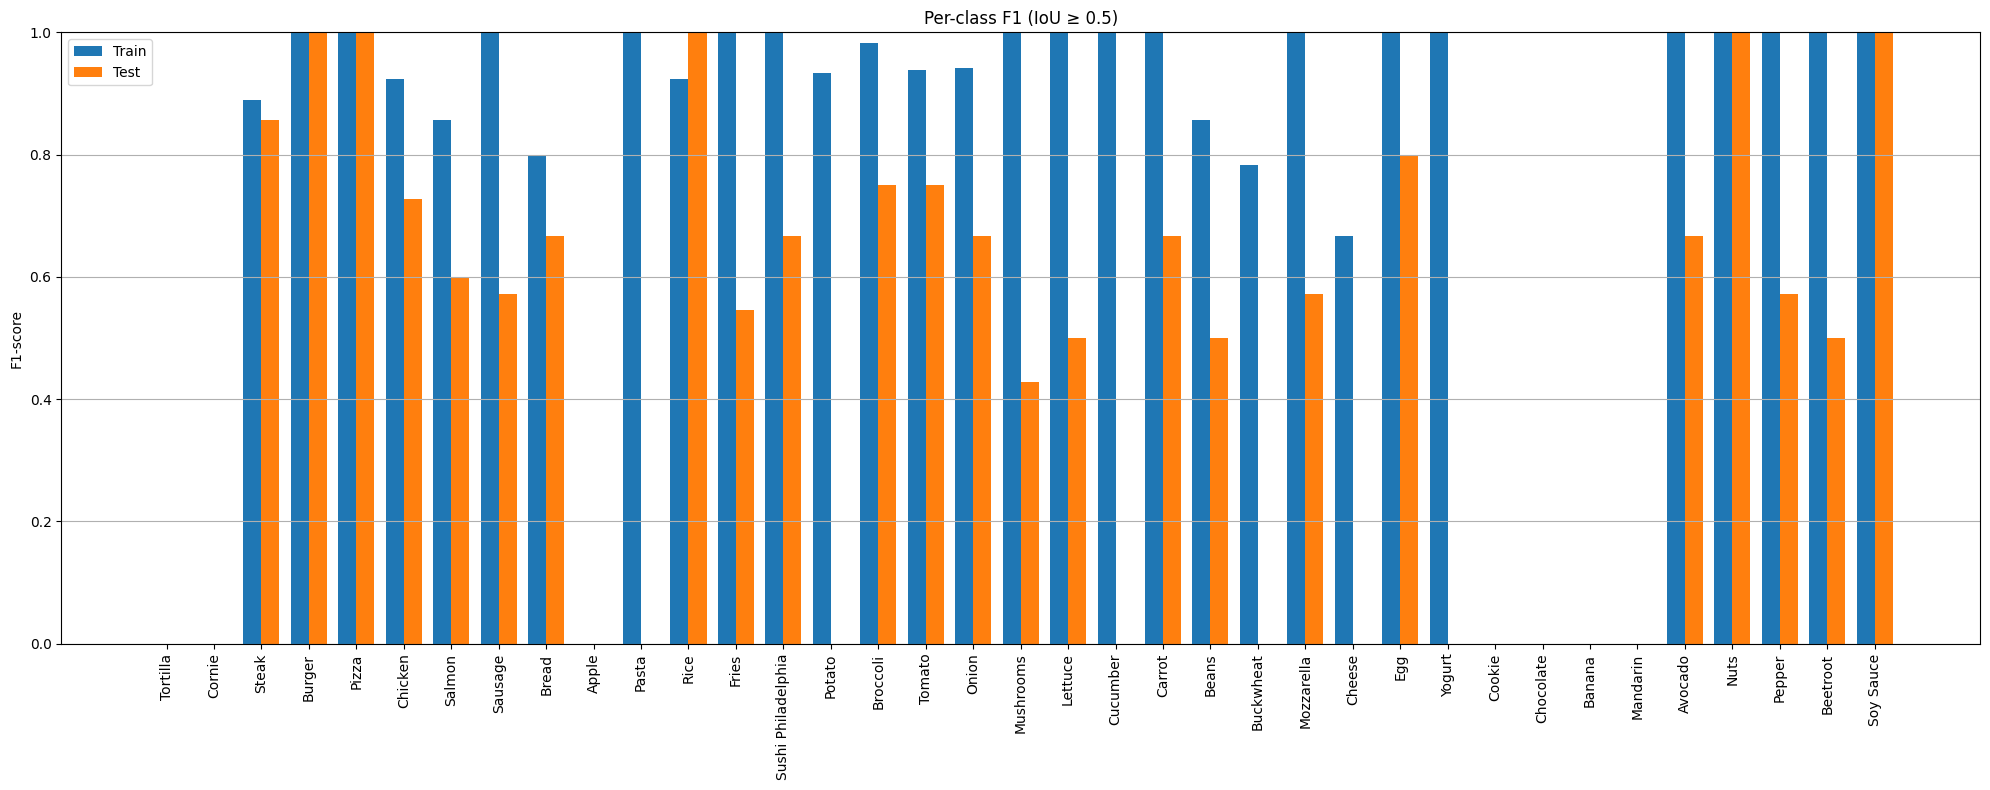


TRAIN
Tortilla             -> F1=0.000, P=0.000, R=0.000
Cornie               -> F1=0.000, P=0.000, R=0.000
Steak                -> F1=0.889, P=0.800, R=1.000
Burger               -> F1=1.000, P=1.000, R=1.000
Pizza                -> F1=1.000, P=1.000, R=1.000
Chicken              -> F1=0.923, P=0.857, R=1.000
Salmon               -> F1=0.857, P=0.750, R=1.000
Sausage              -> F1=1.000, P=1.000, R=1.000
Bread                -> F1=0.800, P=0.667, R=1.000
Apple                -> F1=0.000, P=0.000, R=0.000
Pasta                -> F1=1.000, P=1.000, R=1.000
Rice                 -> F1=0.923, P=0.857, R=1.000
Fries                -> F1=1.000, P=1.000, R=1.000
Sushi Philadelphia   -> F1=1.000, P=1.000, R=1.000
Potato               -> F1=0.933, P=0.875, R=1.000
Broccoli             -> F1=0.982, P=0.964, R=1.000
Tomato               -> F1=0.939, P=0.885, R=1.000
Onion                -> F1=0.941, P=0.889, R=1.000
Mushrooms            -> F1=1.000, P=1.000, R=1.000
Lettuce              -> 

In [48]:
def compute_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)
    if inter <= 0:
        return 0.0

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - inter

    return inter / union if union > 0 else 0.0

def evaluate_per_class_f1(model, cfg, dataset_name, iou_thresh=0.5, score_thresh=0.5):
    dataset_dicts = DatasetCatalog.get(dataset_name)
    class_names = MetadataCatalog.get(dataset_name).thing_classes
    num_classes = len(class_names)

    gt_boxes_all = []
    gt_classes_all = []

    for item in dataset_dicts:
        boxes = []
        classes = []
        for ann in item["annotations"]:
            x, y, w, h = ann["bbox"]
            boxes.append([x, y, x + w, y + h])
            classes.append(ann["category_id"])
        gt_boxes_all.append(np.array(boxes, dtype=np.float32))
        gt_classes_all.append(np.array(classes, dtype=np.int64))

    data_loader = build_detection_test_loader(cfg, dataset_name)

    pred_boxes_all = []
    pred_scores_all = []
    pred_classes_all = []

    model.eval()
    with torch.no_grad():
        for batch in tqdm(data_loader, desc=f"Evaluating {dataset_name}"):
            outputs = model(batch)
            for out in outputs:
                instances = out["instances"].to("cpu")

                boxes = instances.pred_boxes.tensor.numpy() if instances.has("pred_boxes") else np.zeros((0, 4))
                scores = instances.scores.numpy() if instances.has("scores") else np.array([])
                classes = instances.pred_classes.numpy() if instances.has("pred_classes") else np.array([])

                keep = scores >= score_thresh if len(scores) > 0 else np.array([], dtype=bool)

                pred_boxes_all.append(boxes[keep] if len(scores) > 0 else boxes)
                pred_scores_all.append(scores[keep] if len(scores) > 0 else scores)
                pred_classes_all.append(classes[keep] if len(scores) > 0 else classes)

    TP = np.zeros(num_classes)
    FP = np.zeros(num_classes)
    FN = np.zeros(num_classes)

    for i in range(len(gt_boxes_all)):
        gt_boxes = gt_boxes_all[i]
        gt_classes = gt_classes_all[i]

        pred_boxes = pred_boxes_all[i]
        pred_scores = pred_scores_all[i]
        pred_classes = pred_classes_all[i]

        order = np.argsort(-pred_scores) if len(pred_scores) > 0 else np.array([], dtype=int)
        pred_boxes = pred_boxes[order] if len(order) > 0 else pred_boxes
        pred_classes = pred_classes[order] if len(order) > 0 else pred_classes

        matched_gt = set()

        for pred_idx, (pb, pc) in enumerate(zip(pred_boxes, pred_classes)):
            best_iou = 0
            best_gt_idx = None

            for gt_idx, (gb, gc) in enumerate(zip(gt_boxes, gt_classes)):
                if gt_idx in matched_gt:
                    continue

                iou = compute_iou(pb, gb)
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = gt_idx

            if best_gt_idx is not None and best_iou >= iou_thresh:
                gt_cls = gt_classes[best_gt_idx]

                if pc == gt_cls:
                    TP[pc] += 1
                else:
                    FP[pc] += 1
                    FN[gt_cls] += 1

                matched_gt.add(best_gt_idx)
            else:
                FP[pc] += 1

        for gt_idx, gt_cls in enumerate(gt_classes):
            if gt_idx not in matched_gt:
                FN[gt_cls] += 1

    precision = TP / np.maximum(TP + FP, 1e-6)
    recall = TP / np.maximum(TP + FN, 1e-6)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-6)

    return class_names, f1, precision, recall, TP, FP, FN

train_class_names, train_f1, train_prec, train_rec, *_ = evaluate_per_class_f1(
    trainer.model, cfg, "ingredients_train", iou_thresh=0.5, score_thresh=0.5
)

test_class_names, test_f1, test_prec, test_rec, *_ = evaluate_per_class_f1(
    trainer.model, cfg, "ingredients_test", iou_thresh=0.5, score_thresh=0.5
)

x = np.arange(len(train_class_names))
width = 0.38

plt.figure(figsize=(20, 8))
plt.bar(x - width/2, train_f1, width, label="Train")
plt.bar(x + width/2, test_f1, width, label="Test")

plt.xticks(x, train_class_names, rotation=90)
plt.ylim(0, 1)
plt.ylabel("F1-score")
plt.title("Per-class F1 (IoU ≥ 0.5)")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

print("\nTRAIN")
for cname, f1, p, r in zip(train_class_names, train_f1, train_prec, train_rec):
    print(f"{cname:20s} -> F1={f1:.3f}, P={p:.3f}, R={r:.3f}")

print("\nTEST")
for cname, f1, p, r in zip(test_class_names, test_f1, test_prec, test_rec):
    print(f"{cname:20s} -> F1={f1:.3f}, P={p:.3f}, R={r:.3f}")

### GPT + REAL

In [2]:
name_mapping = {
    "Tortilia": "Tortilla",
    "Hard Cheese": "Cheese",
}

In [3]:
import json
from pathlib import Path
from copy import deepcopy


DATASET_DIR = Path("./dataset")

REAL_JSON = DATASET_DIR / "annotations" / "instances_default.json"
GPT_JSON = DATASET_DIR / "annotations_gpt" / "instances_default.json"

OUTPUT_DIR = DATASET_DIR / "merged_annotations"
OUTPUT_DIR.mkdir(exist_ok=True)

FINAL_TRAIN_JSON = OUTPUT_DIR / "final_train.json"
FINAL_TEST_JSON = OUTPUT_DIR / "final_test.json"


REAL_IMAGE_PREFIX = "images"
GPT_IMAGE_PREFIX = "gpt_images"


name_mapping = {
    "Tortilia": "Tortilla",
    "Hard Cheese": "Cheese",
}


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def save_json(data, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)


def build_category_maps(categories):
    id_to_name = {cat["id"]: cat["name"] for cat in categories}
    name_to_id = {cat["name"]: cat["id"] for cat in categories}
    return id_to_name, name_to_id


def add_image_prefix(dataset, prefix):
    dataset = deepcopy(dataset)

    for img in dataset["images"]:
        file_name = img["file_name"]

        if not file_name.startswith(prefix + "/"):
            img["file_name"] = f"{prefix}/{file_name}"

    return dataset


def remap_to_reference_categories(dataset, reference_categories, name_mapping):
    dataset = deepcopy(dataset)

    old_id_to_name, _ = build_category_maps(dataset["categories"])
    _, ref_name_to_id = build_category_maps(reference_categories)

    new_annotations = []

    for ann in dataset["annotations"]:
        old_category_name = old_id_to_name[ann["category_id"]]
        target_category_name = name_mapping.get(old_category_name, old_category_name)

        if target_category_name not in ref_name_to_id:
            print(f"Пропущена аннотация с классом: {old_category_name}")
            continue

        ann["category_id"] = ref_name_to_id[target_category_name]
        new_annotations.append(ann)

    dataset["annotations"] = new_annotations
    dataset["categories"] = reference_categories

    return dataset



def merge_coco_datasets(datasets, reference_categories):
    merged = {
        "licenses": [],
        "info": {},
        "categories": reference_categories,
        "images": [],
        "annotations": []
    }

    next_image_id = 1
    next_annotation_id = 1

    for dataset in datasets:
        image_id_map = {}

        for img in dataset["images"]:
            old_image_id = img["id"]

            new_img = deepcopy(img)
            new_img["id"] = next_image_id

            image_id_map[old_image_id] = next_image_id
            merged["images"].append(new_img)

            next_image_id += 1

        for ann in dataset["annotations"]:
            old_image_id = ann["image_id"]

            if old_image_id not in image_id_map:
                continue

            new_ann = deepcopy(ann)
            new_ann["id"] = next_annotation_id
            new_ann["image_id"] = image_id_map[old_image_id]

            merged["annotations"].append(new_ann)

            next_annotation_id += 1

    return merged


real_dataset = load_json(REAL_JSON)
gpt_dataset = load_json(GPT_JSON)

reference_categories = gpt_dataset["categories"]

real_dataset = add_image_prefix(real_dataset, REAL_IMAGE_PREFIX)
gpt_dataset = add_image_prefix(gpt_dataset, GPT_IMAGE_PREFIX)

real_dataset = remap_to_reference_categories(
    real_dataset,
    reference_categories,
    name_mapping
)

gpt_dataset = remap_to_reference_categories(
    gpt_dataset,
    reference_categories,
    name_mapping
)

gpt_train_dataset = load_json("train_annotations_gpt.json")
gpt_test_dataset = load_json("test_annotations_gpt.json")

final_train = merge_coco_datasets(
    [real_dataset, gpt_train_dataset],
    reference_categories
)

final_test = merge_coco_datasets(
    [gpt_test_dataset],
    reference_categories
)

save_json(final_train, FINAL_TRAIN_JSON)
save_json(final_test, FINAL_TEST_JSON)

print("Готово.")
print(f"Train JSON: {FINAL_TRAIN_JSON}")
print(f"Test JSON: {FINAL_TEST_JSON}")
print(f"Train images: {len(final_train['images'])}")
print(f"Train annotations: {len(final_train['annotations'])}")
print(f"Test images: {len(final_test['images'])}")
print(f"Test annotations: {len(final_test['annotations'])}")

Готово.
Train JSON: dataset/merged_annotations/final_train.json
Test JSON: dataset/merged_annotations/final_test.json
Train images: 383
Train annotations: 1173
Test images: 43
Test annotations: 131


In [4]:
from pathlib import Path
import json

def fix_file_names(json_path):
    json_path = Path(json_path)

    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for img in data["images"]:
        img["file_name"] = Path(img["file_name"]).name

    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)

    print(f"Fixed: {json_path}")


fix_file_names("./dataset/merged_annotations/final_train.json")
fix_file_names("./dataset/merged_annotations/final_test.json")

Fixed: dataset/merged_annotations/final_train.json
Fixed: dataset/merged_annotations/final_test.json


In [5]:
for d in ["ingredients_train", "ingredients_test"]:
    if d in DatasetCatalog.list():
        DatasetCatalog.remove(d)
        MetadataCatalog.remove(d)


register_coco_instances(
    "ingredients_train",
    {},
    "./dataset/merged_annotations/final_train.json",
    "./dataset/all_images"
)


register_coco_instances(
    "ingredients_test",
    {},
    "./dataset/merged_annotations/final_test.json",
    "./dataset/all_images"
)


train_metadata = MetadataCatalog.get("ingredients_train")
test_metadata = MetadataCatalog.get("ingredients_test")

print("Train registered:", DatasetCatalog.get("ingredients_train")[:1])
print("Test registered:", DatasetCatalog.get("ingredients_test")[:1])
print("Classes:", train_metadata.thing_classes)
print("Number of classes:", len(train_metadata.thing_classes))

[05/09 14:11:07 d2.data.datasets.coco]: Loaded 383 images in COCO format from ./dataset/merged_annotations/final_train.json
Train registered: [{'file_name': './dataset/all_images/photo_100_2026-03-29_14-47-55.jpg', 'height': 2560, 'width': 1920, 'image_id': 1, 'annotations': [{'iscrowd': 0, 'bbox': [939.97, 1305.82, 424.35, 410.26], 'category_id': 31, 'segmentation': [[1007.64, 1360.8, 1064.03, 1321.32, 1111.97, 1305.82, 1206.42, 1308.64, 1275.5, 1339.65, 1330.49, 1410.14, 1360.1, 1451.0, 1364.32, 1508.83, 1337.54, 1587.78, 1306.52, 1642.76, 1272.69, 1672.37, 1236.03, 1692.11, 1189.51, 1707.62, 1150.03, 1716.08, 1078.13, 1703.39, 1013.28, 1668.14, 976.62, 1620.21, 951.25, 1559.58, 939.97, 1496.14, 970.98, 1405.91]], 'bbox_mode': <BoxMode.XYWH_ABS: 1>}, {'iscrowd': 0, 'bbox': [325.8, 650.66, 1179.78, 685.53], 'category_id': 30, 'segmentation': [[338.04, 901.61, 419.14, 852.64, 507.89, 717.99, 636.43, 650.66, 830.8, 652.2, 971.54, 687.38, 1138.33, 763.89, 1237.79, 838.87, 1370.92, 962.82

In [8]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
torch.cuda.empty_cache()

from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer

cfg = get_cfg()

base_model = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
cfg.merge_from_file(model_zoo.get_config_file(base_model))

cfg.DATASETS.TRAIN = ("ingredients_train",)
cfg.DATASETS.TEST = ("ingredients_test",)

cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(base_model)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 37
cfg.MODEL.DEVICE = "cuda"

cfg.INPUT.MASK_FORMAT = "bitmask"

# Сильно уменьшаем потребление VRAM
cfg.SOLVER.IMS_PER_BATCH = 1
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 16

cfg.INPUT.MIN_SIZE_TRAIN = (384,)
cfg.INPUT.MAX_SIZE_TRAIN = 512
cfg.INPUT.MIN_SIZE_TEST = 384
cfg.INPUT.MAX_SIZE_TEST = 512

# Можно отключить evaluation во время обучения
cfg.TEST.EVAL_PERIOD = 0

cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 3000
cfg.SOLVER.CHECKPOINT_PERIOD = 500

cfg.OUTPUT_DIR = "./output_mix"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[05/09 14:15:24 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (38, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (38,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (148, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (148,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (37, 256, 1

[05/09 14:15:24 d2.engine.train_loop]: Starting training from iteration 0


/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/detectron2/data/detection_utils.py:449: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)
  torch.stack([torch.from_numpy(np.ascontiguousarray(x)) for x in masks])
/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/detectron2/data/detection_utils.py:449: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of war

[05/09 14:15:25 d2.utils.events]:  eta: 0:01:55  iter: 19  total_loss: 5.283  loss_cls: 3.605  loss_box_reg: 0.9609  loss_mask: 0.6946  loss_rpn_cls: 0.008076  loss_rpn_loc: 0.006303    time: 0.0412  last_time: 0.0371  data_time: 0.0101  last_data_time: 0.0002   lr: 4.9953e-06  max_mem: 688M


/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/detectron2/data/detection_utils.py:449: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)
  torch.stack([torch.from_numpy(np.ascontiguousarray(x)) for x in masks])


[05/09 14:15:26 d2.utils.events]:  eta: 0:01:53  iter: 39  total_loss: 5.202  loss_cls: 3.443  loss_box_reg: 1.042  loss_mask: 0.6921  loss_rpn_cls: 0.01619  loss_rpn_loc: 0.008259    time: 0.0411  last_time: 0.0483  data_time: 0.0018  last_data_time: 0.0021   lr: 9.9902e-06  max_mem: 688M
[05/09 14:15:27 d2.utils.events]:  eta: 0:01:52  iter: 59  total_loss: 4.661  loss_cls: 3.031  loss_box_reg: 0.9328  loss_mask: 0.6918  loss_rpn_cls: 0.02083  loss_rpn_loc: 0.007782    time: 0.0403  last_time: 0.0393  data_time: 0.0018  last_data_time: 0.0060   lr: 1.4985e-05  max_mem: 688M
[05/09 14:15:28 d2.utils.events]:  eta: 0:01:51  iter: 79  total_loss: 4.157  loss_cls: 2.503  loss_box_reg: 0.968  loss_mask: 0.69  loss_rpn_cls: 0.01089  loss_rpn_loc: 0.009057    time: 0.0397  last_time: 0.0367  data_time: 0.0014  last_data_time: 0.0015   lr: 1.998e-05  max_mem: 688M
[05/09 14:15:28 d2.utils.events]:  eta: 0:01:50  iter: 99  total_loss: 3.501  loss_cls: 1.807  loss_box_reg: 0.9811  loss_mask: 0

In [9]:
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

evaluator = COCOEvaluator(
    "ingredients_test",
    cfg,
    False,
    output_dir="./output/eval"
)

val_loader = build_detection_test_loader(cfg, "ingredients_test")

metrics = inference_on_dataset(
    trainer.model,
    val_loader,
    evaluator
)

print(metrics)

[05/09 14:22:35 d2.evaluation.coco_evaluation]: Fast COCO eval is not built. Falling back to official COCO eval.
WARNING [05/09 14:22:35 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
[05/09 14:22:35 d2.data.datasets.coco]: Loaded 43 images in COCO format from ./dataset/merged_annotations/final_test.json
[05/09 14:22:35 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(384, 384), max_size=512, sample_style='choice')]
[05/09 14:22:35 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[05/09 14:22:35 d2.data.common]: Serializing 43 elements to byte tensors and concatenating them all ...
[05/09 14:22:35 d2.data.common]: Serialized dataset takes 0.17 MiB
[05/09 14:22:35 d2.evaluation.evaluator]: Start inference on 43 batches
[05/09 14:22:36 d2.evaluation.evaluator]: Inference done

In [11]:
def compute_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)
    if inter <= 0:
        return 0.0

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0

In [12]:
def evaluate_detection_f1(model, cfg, dataset_name, iou_thresh=0.5, score_thresh=0.5):
    import numpy as np
    import torch
    from tqdm import tqdm
    from detectron2.data import DatasetCatalog, MetadataCatalog, build_detection_test_loader

    dataset_dicts = DatasetCatalog.get(dataset_name)
    class_names = MetadataCatalog.get(dataset_name).thing_classes
    num_classes = len(class_names)

    gt_boxes_all = []
    gt_classes_all = []

    for item in dataset_dicts:
        boxes = []
        classes = []

        for ann in item["annotations"]:
            x, y, w, h = ann["bbox"]
            boxes.append([x, y, x + w, y + h])
            classes.append(ann["category_id"])

        gt_boxes_all.append(np.array(boxes, dtype=np.float32))
        gt_classes_all.append(np.array(classes, dtype=np.int64))

    data_loader = build_detection_test_loader(cfg, dataset_name)

    pred_boxes_all = []
    pred_scores_all = []
    pred_classes_all = []

    model.eval()

    with torch.no_grad():
        for batch in tqdm(data_loader, desc=f"Evaluating {dataset_name}"):
            outputs = model(batch)

            for out in outputs:
                instances = out["instances"].to("cpu")

                boxes = instances.pred_boxes.tensor.numpy() if instances.has("pred_boxes") else np.zeros((0, 4))
                scores = instances.scores.numpy() if instances.has("scores") else np.array([])
                classes = instances.pred_classes.numpy() if instances.has("pred_classes") else np.array([])

                keep = scores >= score_thresh

                pred_boxes_all.append(boxes[keep])
                pred_scores_all.append(scores[keep])
                pred_classes_all.append(classes[keep])

    TP = np.zeros(num_classes)
    FP = np.zeros(num_classes)
    FN = np.zeros(num_classes)

    for i in range(len(gt_boxes_all)):
        gt_boxes = gt_boxes_all[i]
        gt_classes = gt_classes_all[i]

        pred_boxes = pred_boxes_all[i]
        pred_scores = pred_scores_all[i]
        pred_classes = pred_classes_all[i]

        order = np.argsort(-pred_scores)
        pred_boxes = pred_boxes[order]
        pred_classes = pred_classes[order]

        matched_gt = set()

        for pb, pc in zip(pred_boxes, pred_classes):
            best_iou = 0
            best_gt_idx = None

            for gt_idx, (gb, gc) in enumerate(zip(gt_boxes, gt_classes)):
                if gt_idx in matched_gt:
                    continue

                # ВАЖНО: сравниваем только с тем же классом
                if pc != gc:
                    continue

                iou = compute_iou(pb, gb)

                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = gt_idx

            if best_gt_idx is not None and best_iou >= iou_thresh:
                TP[pc] += 1
                matched_gt.add(best_gt_idx)
            else:
                FP[pc] += 1

        for gt_idx, gt_cls in enumerate(gt_classes):
            if gt_idx not in matched_gt:
                FN[gt_cls] += 1

    precision = TP / np.maximum(TP + FP, 1e-6)
    recall = TP / np.maximum(TP + FN, 1e-6)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-6)

    macro_precision = precision.mean()
    macro_recall = recall.mean()
    macro_f1 = f1.mean()

    micro_TP = TP.sum()
    micro_FP = FP.sum()
    micro_FN = FN.sum()

    micro_precision = micro_TP / max(micro_TP + micro_FP, 1e-6)
    micro_recall = micro_TP / max(micro_TP + micro_FN, 1e-6)
    micro_f1 = 2 * micro_precision * micro_recall / max(micro_precision + micro_recall, 1e-6)

    return {
        "class_names": class_names,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "micro_precision": micro_precision,
        "micro_recall": micro_recall,
        "micro_f1": micro_f1,
    }

In [13]:
train_res = evaluate_detection_f1(
    trainer.model,
    cfg,
    "ingredients_train",
    iou_thresh=0.5,
    score_thresh=0.5
)

test_res = evaluate_detection_f1(
    trainer.model,
    cfg,
    "ingredients_test",
    iou_thresh=0.5,
    score_thresh=0.5
)

[05/09 14:23:51 d2.data.datasets.coco]: Loaded 383 images in COCO format from ./dataset/merged_annotations/final_train.json
[05/09 14:23:51 d2.data.datasets.coco]: Loaded 383 images in COCO format from ./dataset/merged_annotations/final_train.json
[05/09 14:23:51 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(384, 384), max_size=512, sample_style='choice')]
[05/09 14:23:51 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[05/09 14:23:51 d2.data.common]: Serializing 383 elements to byte tensors and concatenating them all ...
[05/09 14:23:51 d2.data.common]: Serialized dataset takes 1.61 MiB


Evaluating ingredients_train: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 383/383 [00:11<00:00, 33.68it/s]


[05/09 14:24:02 d2.data.datasets.coco]: Loaded 43 images in COCO format from ./dataset/merged_annotations/final_test.json
[05/09 14:24:02 d2.data.datasets.coco]: Loaded 43 images in COCO format from ./dataset/merged_annotations/final_test.json
[05/09 14:24:02 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(384, 384), max_size=512, sample_style='choice')]
[05/09 14:24:02 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[05/09 14:24:02 d2.data.common]: Serializing 43 elements to byte tensors and concatenating them all ...
[05/09 14:24:02 d2.data.common]: Serialized dataset takes 0.17 MiB


Evaluating ingredients_test: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 43/43 [00:01<00:00, 31.63it/s]


In [14]:
print("TRAIN")
print("Macro Precision:", train_res["macro_precision"])
print("Macro Recall:", train_res["macro_recall"])
print("Macro F1:", train_res["macro_f1"])
print("Micro Precision:", train_res["micro_precision"])
print("Micro Recall:", train_res["micro_recall"])
print("Micro F1:", train_res["micro_f1"])

print("\nTEST")
print("Macro Precision:", test_res["macro_precision"])
print("Macro Recall:", test_res["macro_recall"])
print("Macro F1:", test_res["macro_f1"])
print("Micro Precision:", test_res["micro_precision"])
print("Micro Recall:", test_res["micro_recall"])
print("Micro F1:", test_res["micro_f1"])

TRAIN
Macro Precision: 0.9115435752158015
Macro Recall: 0.935687123922418
Macro F1: 0.9175027327161224
Micro Precision: 0.9400499583680266
Micro Recall: 0.9624893435635123
Micro F1: 0.9511373209772536

TEST
Macro Precision: 0.5658680658680658
Macro Recall: 0.5927927927927928
Macro F1: 0.5403879153879154
Micro Precision: 0.6302521008403361
Micro Recall: 0.5725190839694656
Micro F1: 0.6


### second experiment

In [17]:
import json
import random
from pathlib import Path
from copy import deepcopy
from collections import defaultdict


DATASET_DIR = Path("./dataset")

REAL_JSON = DATASET_DIR / "annotations" / "instances_default.json"
GPT_TRAIN_JSON = Path("train_annotations_gpt.json")
GPT_TEST_JSON = Path("test_annotations_gpt.json")

OUTPUT_DIR = DATASET_DIR / "merged_annotations"
OUTPUT_DIR.mkdir(exist_ok=True)

FINAL_TRAIN_JSON = OUTPUT_DIR / "final_train.json"
FINAL_TEST_JSON = OUTPUT_DIR / "final_test.json"

REAL_TEST_GROUPS_TARGET = 5

FORCE_TEST_CLASSES = {
    "Buckwheat",
    "Banana",
}

name_mapping = {
    "Tortilia": "Tortilla",
    "Hard Cheese": "Cheese",
}


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def save_json(data, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)


def build_category_maps(categories):
    id_to_name = {cat["id"]: cat["name"] for cat in categories}
    name_to_id = {cat["name"]: cat["id"] for cat in categories}
    return id_to_name, name_to_id


def clean_file_names(dataset):
    dataset = deepcopy(dataset)

    for img in dataset["images"]:
        file_name = img["file_name"]

        # оставляем только имя файла, без gpt_images/, images/ и других папок
        img["file_name"] = Path(file_name).name

    return dataset


def remap_to_reference_categories(dataset, reference_categories, name_mapping):
    dataset = deepcopy(dataset)

    old_id_to_name, _ = build_category_maps(dataset["categories"])
    _, ref_name_to_id = build_category_maps(reference_categories)

    new_annotations = []

    for ann in dataset["annotations"]:
        old_category_name = old_id_to_name[ann["category_id"]]
        target_category_name = name_mapping.get(old_category_name, old_category_name)

        if target_category_name not in ref_name_to_id:
            print(f"Пропущена аннотация с классом: {old_category_name}")
            continue

        ann["category_id"] = ref_name_to_id[target_category_name]
        new_annotations.append(ann)

    dataset["annotations"] = new_annotations
    dataset["categories"] = reference_categories

    return dataset


def split_coco_by_ingredient_groups(dataset, test_groups_target=5, force_test_classes=None):
    dataset = deepcopy(dataset)

    if force_test_classes is None:
        force_test_classes = set()

    id_to_name, _ = build_category_maps(dataset["categories"])

    anns_by_image = defaultdict(list)
    for ann in dataset["annotations"]:
        anns_by_image[ann["image_id"]].append(ann)

    groups = defaultdict(list)

    for img in dataset["images"]:
        image_id = img["id"]

        class_names = []
        for ann in anns_by_image[image_id]:
            class_name = id_to_name[ann["category_id"]]
            class_names.append(class_name)

        group_key = tuple(sorted(set(class_names)))
        groups[group_key].append(img)

    all_group_keys = list(groups.keys())
    test_group_keys = set()

    for group_key in all_group_keys:
        if any(cls in group_key for cls in force_test_classes):
            test_group_keys.add(group_key)

    remaining_group_keys = [
        g for g in all_group_keys
        if g not in test_group_keys
    ]

    random.seed(42)
    random.shuffle(remaining_group_keys)

    while len(test_group_keys) < test_groups_target and remaining_group_keys:
        test_group_keys.add(remaining_group_keys.pop())

    train_image_ids = set()
    test_image_ids = set()

    for group_key, images in groups.items():
        ids = [img["id"] for img in images]

        if group_key in test_group_keys:
            test_image_ids.update(ids)
        else:
            train_image_ids.update(ids)

    def build_subset(image_ids):
        subset_images = [
            deepcopy(img)
            for img in dataset["images"]
            if img["id"] in image_ids
        ]

        subset_annotations = [
            deepcopy(ann)
            for ann in dataset["annotations"]
            if ann["image_id"] in image_ids
        ]

        return {
            "licenses": dataset.get("licenses", []),
            "info": dataset.get("info", {}),
            "categories": dataset["categories"],
            "images": subset_images,
            "annotations": subset_annotations,
        }

    train_dataset = build_subset(train_image_ids)
    test_dataset = build_subset(test_image_ids)

    print("\nREAL split by ingredient groups")
    print(f"Total groups: {len(all_group_keys)}")
    print(f"Train groups: {len(all_group_keys) - len(test_group_keys)}")
    print(f"Test groups: {len(test_group_keys)}")

    print("\nTest groups:")
    for group_key in sorted(test_group_keys):
        print(" -", group_key, "| images:", len(groups[group_key]))

    print(f"\nReal train images: {len(train_dataset['images'])}")
    print(f"Real train annotations: {len(train_dataset['annotations'])}")
    print(f"Real test images: {len(test_dataset['images'])}")
    print(f"Real test annotations: {len(test_dataset['annotations'])}")

    return train_dataset, test_dataset


def merge_coco_datasets(datasets, reference_categories):
    merged = {
        "licenses": [],
        "info": {},
        "categories": reference_categories,
        "images": [],
        "annotations": []
    }

    next_image_id = 1
    next_annotation_id = 1

    for dataset in datasets:
        image_id_map = {}

        for img in dataset["images"]:
            old_image_id = img["id"]

            new_img = deepcopy(img)
            new_img["id"] = next_image_id

            image_id_map[old_image_id] = next_image_id
            merged["images"].append(new_img)

            next_image_id += 1

        for ann in dataset["annotations"]:
            old_image_id = ann["image_id"]

            if old_image_id not in image_id_map:
                continue

            new_ann = deepcopy(ann)
            new_ann["id"] = next_annotation_id
            new_ann["image_id"] = image_id_map[old_image_id]

            merged["annotations"].append(new_ann)

            next_annotation_id += 1

    return merged


real_dataset = load_json(REAL_JSON)
gpt_train_dataset = load_json(GPT_TRAIN_JSON)
gpt_test_dataset = load_json(GPT_TEST_JSON)

reference_categories = gpt_train_dataset["categories"]

real_dataset = clean_file_names(real_dataset)
gpt_train_dataset = clean_file_names(gpt_train_dataset)
gpt_test_dataset = clean_file_names(gpt_test_dataset)

real_dataset = remap_to_reference_categories(
    real_dataset,
    reference_categories,
    name_mapping
)

gpt_train_dataset = remap_to_reference_categories(
    gpt_train_dataset,
    reference_categories,
    name_mapping
)

gpt_test_dataset = remap_to_reference_categories(
    gpt_test_dataset,
    reference_categories,
    name_mapping
)

real_train_dataset, real_test_dataset = split_coco_by_ingredient_groups(
    real_dataset,
    test_groups_target=REAL_TEST_GROUPS_TARGET,
    force_test_classes=FORCE_TEST_CLASSES
)

final_train = merge_coco_datasets(
    [real_train_dataset, gpt_train_dataset],
    reference_categories
)

final_test = merge_coco_datasets(
    [real_test_dataset, gpt_test_dataset],
    reference_categories
)

save_json(final_train, FINAL_TRAIN_JSON)
save_json(final_test, FINAL_TEST_JSON)

print("\nГотово.")
print(f"Train JSON: {FINAL_TRAIN_JSON}")
print(f"Test JSON: {FINAL_TEST_JSON}")
print(f"Train images: {len(final_train['images'])}")
print(f"Train annotations: {len(final_train['annotations'])}")
print(f"Test images: {len(final_test['images'])}")
print(f"Test annotations: {len(final_test['annotations'])}")


REAL split by ingredient groups
Total groups: 85
Train groups: 66
Test groups: 19

Test groups:
 - ('Apple', 'Avocado', 'Banana', 'Carrot') | images: 4
 - ('Apple', 'Banana', 'Chocolate') | images: 3
 - ('Apple', 'Banana', 'Cookie', 'Mandarin') | images: 3
 - ('Apple', 'Banana', 'Mandarin') | images: 3
 - ('Avocado', 'Banana', 'Carrot') | images: 5
 - ('Avocado', 'Banana', 'Tomato') | images: 8
 - ('Banana', 'Carrot', 'Cornie') | images: 3
 - ('Banana', 'Carrot', 'Mandarin') | images: 3
 - ('Banana', 'Carrot', 'Tomato') | images: 2
 - ('Banana', 'Chocolate', 'Cookie') | images: 3
 - ('Banana', 'Chocolate', 'Cornie') | images: 3
 - ('Banana', 'Chocolate', 'Mandarin') | images: 3
 - ('Banana', 'Cookie', 'Mandarin') | images: 3
 - ('Banana', 'Tortilla', 'Yogurt') | images: 3
 - ('Buckwheat', 'Chicken', 'Cornie') | images: 3
 - ('Buckwheat', 'Chicken', 'Egg') | images: 3
 - ('Buckwheat', 'Chicken', 'Rice') | images: 3
 - ('Buckwheat', 'Chicken', 'Rice', 'Sausage') | images: 3
 - ('Buckwhe

In [18]:
register_coco_instances(
    "mix_train",
    {},
    "dataset/merged_annotations/final_train.json",
    "dataset/all_images"
)

register_coco_instances(
    "mix_test",
    {},
    "dataset/merged_annotations/final_test.json",
    "dataset/all_images"
)

In [22]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
torch.cuda.empty_cache()

from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer

cfg = get_cfg()

base_model = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
cfg.merge_from_file(model_zoo.get_config_file(base_model))

cfg.DATASETS.TRAIN = ("mix_train",)
cfg.DATASETS.TEST = ("mix_test",)

cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(base_model)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 37
cfg.MODEL.DEVICE = "cuda"

cfg.INPUT.MASK_FORMAT = "bitmask"

# Сильно уменьшаем потребление VRAM
cfg.SOLVER.IMS_PER_BATCH = 1

cfg.INPUT.MIN_SIZE_TRAIN = (384,)
cfg.INPUT.MAX_SIZE_TRAIN = 512
cfg.INPUT.MIN_SIZE_TEST = 384
cfg.INPUT.MAX_SIZE_TEST = 512

# Можно отключить evaluation во время обучения
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 10000

cfg.SOLVER.STEPS = (6000, 8500)
cfg.SOLVER.GAMMA = 0.1

cfg.SOLVER.WARMUP_ITERS = 500
cfg.SOLVER.WARMUP_FACTOR = 0.001

cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 64
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.3

cfg.TEST.EVAL_PERIOD = 500

cfg.OUTPUT_DIR = "./output_mix"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[05/09 14:48:45 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (38, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (38,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (148, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (148,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (37, 256, 1

[05/09 14:48:45 d2.engine.train_loop]: Starting training from iteration 0


/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/detectron2/data/detection_utils.py:449: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)
  torch.stack([torch.from_numpy(np.ascontiguousarray(x)) for x in masks])
/home/podolska/miniconda/envs/detectron/lib/python3.10/site-packages/detectron2/data/detection_utils.py:449: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of war

[05/09 14:48:46 d2.utils.events]:  eta: 0:06:51  iter: 19  total_loss: 5.318  loss_cls: 3.585  loss_box_reg: 0.964  loss_mask: 0.693  loss_rpn_cls: 0.01928  loss_rpn_loc: 0.006912    time: 0.0420  last_time: 0.0400  data_time: 0.0100  last_data_time: 0.0014   lr: 9.7405e-06  max_mem: 4257M
[05/09 14:48:47 d2.utils.events]:  eta: 0:06:47  iter: 39  total_loss: 4.865  loss_cls: 3.272  loss_box_reg: 0.9624  loss_mask: 0.6889  loss_rpn_cls: 0.01842  loss_rpn_loc: 0.00819    time: 0.0417  last_time: 0.0401  data_time: 0.0017  last_data_time: 0.0003   lr: 1.973e-05  max_mem: 4257M
[05/09 14:48:48 d2.utils.events]:  eta: 0:06:43  iter: 59  total_loss: 4.279  loss_cls: 2.55  loss_box_reg: 0.9585  loss_mask: 0.6873  loss_rpn_cls: 0.01577  loss_rpn_loc: 0.00534    time: 0.0417  last_time: 0.0401  data_time: 0.0016  last_data_time: 0.0017   lr: 2.972e-05  max_mem: 4257M
[05/09 14:48:49 d2.utils.events]:  eta: 0:06:46  iter: 79  total_loss: 3.183  loss_cls: 1.511  loss_box_reg: 0.9753  loss_mask: 

In [27]:
train_res = evaluate_detection_f1(
    trainer.model,
    cfg,
    "mix_train",
    iou_thresh=0.6,
    score_thresh=0.8
)

test_res = evaluate_detection_f1(
    trainer.model,
    cfg,
    "mix_test",
    iou_thresh=0.6,
    score_thresh=0.8
)

[05/09 14:57:42 d2.data.datasets.coco]: Loaded 319 images in COCO format from dataset/merged_annotations/final_train.json
[05/09 14:57:42 d2.data.datasets.coco]: Loaded 319 images in COCO format from dataset/merged_annotations/final_train.json
[05/09 14:57:42 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(384, 384), max_size=512, sample_style='choice')]
[05/09 14:57:42 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[05/09 14:57:42 d2.data.common]: Serializing 319 elements to byte tensors and concatenating them all ...
[05/09 14:57:42 d2.data.common]: Serialized dataset takes 1.29 MiB


Evaluating mix_train: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████| 319/319 [00:08<00:00, 36.33it/s]

[05/09 14:57:50 d2.data.datasets.coco]: Loaded 107 images in COCO format from dataset/merged_annotations/final_test.json
[05/09 14:57:50 d2.data.datasets.coco]: Loaded 107 images in COCO format from dataset/merged_annotations/final_test.json
[05/09 14:57:50 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(384, 384), max_size=512, sample_style='choice')]
[05/09 14:57:50 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[05/09 14:57:50 d2.data.common]: Serializing 107 elements to byte tensors and concatenating them all ...


[05/09 14:57:50 d2.data.common]: Serialized dataset takes 0.49 MiB


Evaluating mix_test: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 107/107 [00:03<00:00, 33.99it/s]


In [28]:
print("TRAIN")
print("Macro Precision:", train_res["macro_precision"])
print("Macro Recall:", train_res["macro_recall"])
print("Macro F1:", train_res["macro_f1"])
print("Micro Precision:", train_res["micro_precision"])
print("Micro Recall:", train_res["micro_recall"])
print("Micro F1:", train_res["micro_f1"])

print("\nTEST")
print("Macro Precision:", test_res["macro_precision"])
print("Macro Recall:", test_res["macro_recall"])
print("Macro F1:", test_res["macro_f1"])
print("Micro Precision:", test_res["micro_precision"])
print("Micro Recall:", test_res["micro_recall"])
print("Micro F1:", test_res["micro_f1"])

TRAIN
Macro Precision: 0.9232008531458478
Macro Recall: 0.9574612206191152
Macro F1: 0.9352120014745213
Micro Precision: 0.9609218436873748
Micro Recall: 0.9876416065911432
Micro F1: 0.9740985271711529

TEST
Macro Precision: 0.762625675125675
Macro Recall: 0.7373600873600873
Macro F1: 0.7281943682856007
Micro Precision: 0.8659003831417624
Micro Recall: 0.6786786786786787
Micro F1: 0.7609427609427609
